In [7]:
import csv
from datetime import datetime, timedelta
import random
import pandas as pd

NUM_RECORDS = 500
ANOMALY_RATE = 0.15  # 15% anomaly rate
OUTPUT_FILENAME = "employee_access_dataset.csv"

FIRST_NAMES = [
    "Alice",
    "Liam",
    "Sophia",
    "James",
    "Diana",
    "Olivia",
    "Benjamin",
    "Charlotte",
    "Ian",
    "Lucas",
    "Mia",
    "Noah",
    "Bob",
    "Harper",
    "Charlie",
    "Ethan",
    "Fiona",
    "George",
    "Hannah",
    "Julia",
]
LAST_NAMES = [
    "Smith",
    "Davis",
    "Taylor",
    "Wilson",
    "Prince",
    "Martinez",
    "Moore",
    "Anderson",
    "Malcolm",
    "Thomas",
    "Jackson",
    "White",
    "Jones",
    "Harris",
    "Brown",
    "Hunt",
    "Gallagher",
    "Castanza",
    "Abbott",
    "Roberts",
]

# Generate a pool of 50 unique workers
workers = []
used_ids = set()
for _ in range(50):
  while True:
    worker_id = random.randint(10000, 99999)
    if worker_id not in used_ids:
      used_ids.add(worker_id)
      break
  name = f"{random.choice(FIRST_NAMES)} {random.choice(LAST_NAMES)}"
  workers.append((str(worker_id), name))

num_anomalies = int(NUM_RECORDS * ANOMALY_RATE)
num_benign = NUM_RECORDS - num_anomalies

# Diversity split: ~85% during closed hours, ~15% during normal hours
num_closed_anomalies = int(num_anomalies * 0.85)
num_day_anomalies = num_anomalies - num_closed_anomalies

records = []
start_date = datetime(2026, 11, 1, 0, 0, 0)

# 1. Generate Benign Records (Standard working hours: 08:00 - 18:00)
for _ in range(num_benign):
  worker = random.choice(workers)
  day_offset = random.randint(0, 2)
  hour_offset = random.randint(8, 17)
  timestamp = start_date + timedelta(
      days=day_offset,
      hours=hour_offset,
      minutes=random.randint(0, 59),
      seconds=random.randint(0, 59),
  )
  records.append({
      "Worker ID": worker[0],
      "Name": worker[1],
      "Timestamp": timestamp.strftime("%Y-%m-%d %H:%M:%S"),
      "Anomaly": "No",
  })

# 2. Closed-Hour Anomalies (20:00 - 06:00)
closed_hours = [20, 21, 22, 23, 0, 1, 2, 3, 4, 5]
for _ in range(num_closed_anomalies):
  worker = random.choice(workers)
  day_offset = random.randint(0, 2)
  hour_offset = random.choice(closed_hours)
  actual_day_offset = day_offset + 1 if hour_offset < 6 else day_offset

  timestamp = start_date + timedelta(
      days=actual_day_offset,
      hours=hour_offset,
      minutes=random.randint(0, 59),
      seconds=random.randint(0, 59),
  )
  records.append({
      "Worker ID": worker[0],
      "Name": worker[1],
      "Timestamp": timestamp.strftime("%Y-%m-%d %H:%M:%S"),
      "Anomaly": "Yes",
  })

# 3. Sneaky Daytime Anomalies (08:00 - 18:00)
for _ in range(num_day_anomalies):
  worker = random.choice(workers)
  day_offset = random.randint(0, 2)
  hour_offset = random.randint(8, 17)

  timestamp = start_date + timedelta(
      days=day_offset,
      hours=hour_offset,
      minutes=random.randint(0, 59),
      seconds=random.randint(0, 59),
  )
  records.append({
      "Worker ID": worker[0],
      "Name": worker[1],
      "Timestamp": timestamp.strftime("%Y-%m-%d %H:%M:%S"),
      "Anomaly": "Yes",
  })

random.shuffle(records)

with open(OUTPUT_FILENAME, mode="w", newline="", encoding="utf-8") as file:
  writer = csv.DictWriter(
      file, fieldnames=["Worker ID", "Name", "Timestamp", "Anomaly"]
  )
  writer.writeheader()
  writer.writerows(records)

# Display a preview of the generated records
df_preview = pd.DataFrame(records)
print(df_preview.head(15).to_string(index=False))

Worker ID             Name           Timestamp Anomaly
    62715      Diana Moore 2026-11-02 16:07:55      No
    11311     Ian Anderson 2026-11-03 09:42:40     Yes
    83823     George Moore 2026-11-01 16:51:05      No
    68938      Liam Harris 2026-11-01 17:05:40      No
    87595  Sophia Martinez 2026-11-03 08:33:02      No
    68702    Ethan Malcolm 2026-11-01 10:26:42      No
    25586  Sophia Castanza 2026-11-02 14:50:43      No
    60417 Harper Gallagher 2026-11-03 16:56:05      No
    81676      Bob Jackson 2026-11-03 16:14:38      No
    11319    Julia Roberts 2026-11-03 08:42:26      No
    54593       Mia Prince 2026-11-03 14:07:31      No
    21532   Lucas Martinez 2026-11-02 11:27:44      No
    61033        Ian Smith 2026-11-03 08:57:29      No
    11508      Ethan Smith 2026-11-03 10:08:32      No
    20876   Sophia Malcolm 2026-11-03 03:34:08     Yes


## Isolation Forest

CLASSIFICATION PERFORMANCE METRICS TABLE:
              precision  recall  f1-score  support
Normal            0.973   0.840     0.902  425.000
Anomaly           0.489   0.867     0.625   75.000
accuracy          0.844   0.844     0.844    0.844
macro avg         0.731   0.853     0.763  500.000
weighted avg      0.900   0.844     0.860  500.000


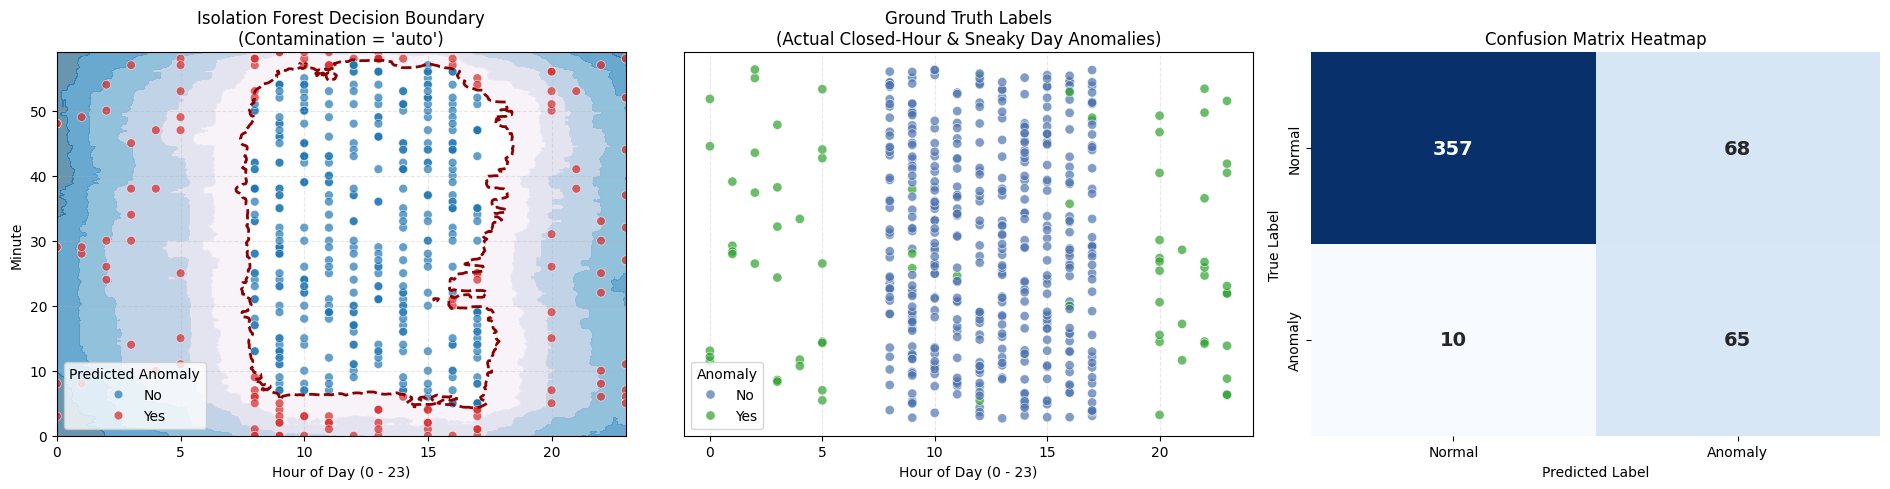

In [8]:
import random
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.ensemble import IsolationForest
from sklearn.metrics import classification_report, confusion_matrix

# 1. Load data
df = pd.read_csv("employee_access_dataset.csv")

# 2. Feature Engineering & Jitter for clearer visualization
df["Timestamp"] = pd.to_datetime(df["Timestamp"])
df["hour"] = df["Timestamp"].dt.hour
df["minute"] = df["Timestamp"].dt.minute
df["jitter"] = [random.uniform(-0.4, 0.4) for _ in range(len(df))]

# 3. Train Isolation Forest Model with contamination='auto' (Realistic unsupervised mode)
X = df[["hour", "minute"]].values
model = IsolationForest(contamination="auto", random_state=42)
df["model_score"] = model.fit_predict(X)
df["Predicted Anomaly"] = df["model_score"].apply(
    lambda x: "Yes" if x == -1 else "No"
)

# 4. Generate Classification Report as a Clean Table
report_dict = classification_report(
    df["Anomaly"],
    df["Predicted Anomaly"],
    target_names=["Normal", "Anomaly"],
    output_dict=True,
)
metrics_df = pd.DataFrame(report_dict).transpose()

print("=" * 65)
print("CLASSIFICATION PERFORMANCE METRICS TABLE:")
print("=" * 65)
print(metrics_df.round(3).to_string())
print("=" * 65)

# 5. Advanced Visualizations (3 Panel Dashboard)
fig, axes = plt.subplots(1, 3, figsize=(19, 5))

# --- Panel 1: Isolation Forest Decision Boundaries ---
xx, yy = np.meshgrid(np.linspace(0, 23, 200), np.linspace(0, 59, 200))
Z = model.decision_function(np.c_[xx.ravel(), yy.ravel()])
Z = Z.reshape(xx.shape)

axes[0].contourf(
    xx,
    yy,
    Z,
    levels=np.linspace(Z.min(), 0, 7),
    cmap=plt.cm.PuBu_r,
    alpha=0.6,
)
axes[0].contour(
    xx, yy, Z, levels=[0], linewidths=2, colors="darkred", linestyles="--"
)
sns.scatterplot(
    data=df,
    x="hour",
    y="minute",
    hue="Predicted Anomaly",
    palette={"No": "#1f77b4", "Yes": "#d62728"},
    alpha=0.7,
    s=40,
    ax=axes[0],
)
axes[0].set_title(
    "Isolation Forest Decision Boundary\n(Contamination = 'auto')"
)
axes[0].set_xlabel("Hour of Day (0 - 23)")
axes[0].set_ylabel("Minute")
axes[0].grid(True, linestyle="--", alpha=0.3)

# --- Panel 2: Ground Truth Scatter Plot ---
sns.scatterplot(
    data=df,
    x="hour",
    y="jitter",
    hue="Anomaly",
    palette={"No": "#4c72b0", "Yes": "#2ca02c"},
    alpha=0.7,
    s=45,
    ax=axes[1],
)
axes[1].set_title(
    "Ground Truth Labels\n(Actual Closed-Hour & Sneaky Day Anomalies)"
)
axes[1].set_xlabel("Hour of Day (0 - 23)")
axes[1].set_ylabel("")
axes[1].set_yticks([])
axes[1].grid(True, linestyle="--", alpha=0.3)

# --- Panel 3: Confusion Matrix Heatmap ---
cm = confusion_matrix(df["Anomaly"], df["Predicted Anomaly"], labels=["No", "Yes"])
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    cbar=False,
    xticklabels=["Normal", "Anomaly"],
    yticklabels=["Normal", "Anomaly"],
    annot_kws={"size": 14, "weight": "bold"},
    ax=axes[2],
)
axes[2].set_title("Confusion Matrix Heatmap")
axes[2].set_xlabel("Predicted Label")
axes[2].set_ylabel("True Label")

plt.tight_layout()
plt.show()

## Auto Encoder

c:\Users\User\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (600) reached and the optimization hasn't converged yet.
  warnings.warn(


Autoencoder Reconstruction Error Threshold (85th pct): 0.7393
              precision    recall  f1-score   support

      Normal       0.92      0.92      0.92       425
     Anomaly       0.54      0.55      0.54        75

    accuracy                           0.86       500
   macro avg       0.73      0.73      0.73       500
weighted avg       0.86      0.86      0.86       500



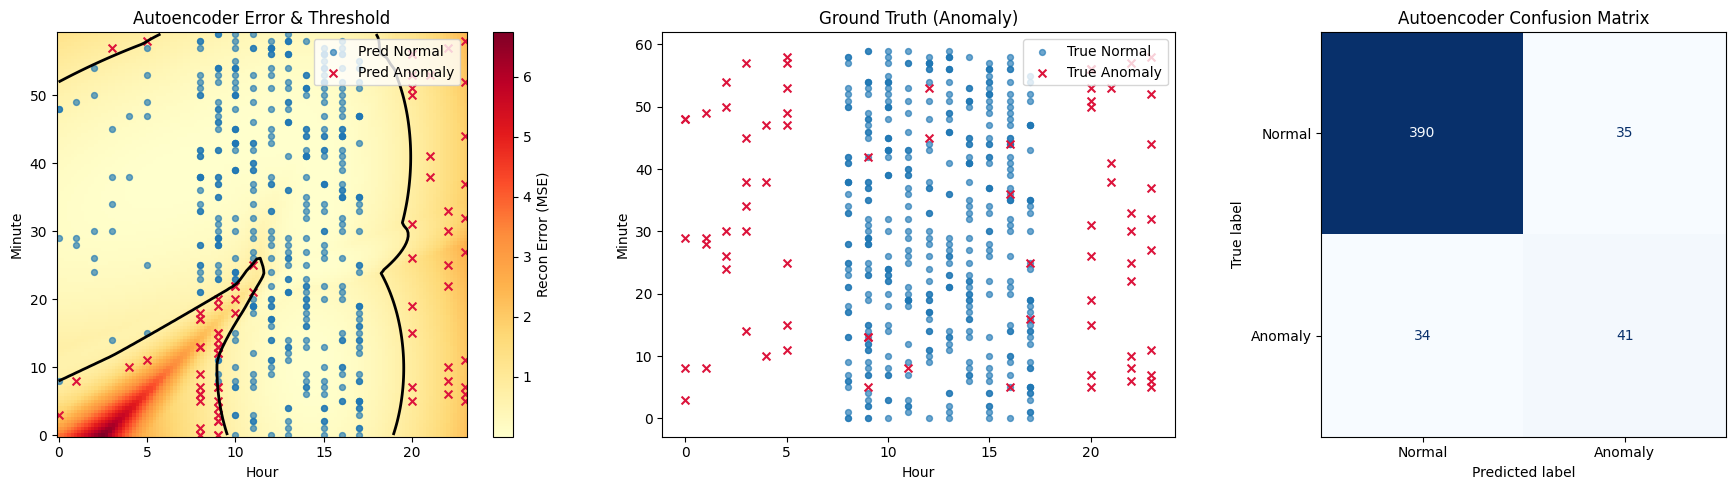

In [9]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPRegressor
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

# Features & ground-truth labels
features = ["hour", "minute"]
X_ae = df[features].copy()
y_true_ae = (df["Anomaly"] == "Yes").astype(int)  # 1 = Anomaly, 0 = Normal

# Scale features for neural network training
ae_scaler = StandardScaler()
X_ae_scaled = ae_scaler.fit_transform(X_ae)

# Autoencoder (bottleneck: 2 -> 8 -> 2 -> 8 -> 2)
ae_model = MLPRegressor(
    hidden_layer_sizes=(8, 2, 8),
    activation="relu",
    solver="adam",
    max_iter=600,
    random_state=42,
)
ae_model.fit(X_ae_scaled, X_ae_scaled)

# Reconstruction error (MSE) & threshold-based anomaly prediction
ae_recon = ae_model.predict(X_ae_scaled)
ae_recon_error = np.mean((X_ae_scaled - ae_recon) ** 2, axis=1)

ae_threshold = np.percentile(ae_recon_error, 85)
ae_y_pred = (ae_recon_error >= ae_threshold).astype(int)  # 1 = Anomaly, 0 = Normal

print(f"Autoencoder Reconstruction Error Threshold (85th pct): {ae_threshold:.4f}")
print(classification_report(y_true_ae, ae_y_pred, target_names=["Normal", "Anomaly"]))

# 3-Panel Dashboard
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Panel 1: Reconstruction error surface & threshold contour
hour_grid, min_grid = np.meshgrid(
    np.linspace(df["hour"].min(), df["hour"].max(), 120),
    np.linspace(df["minute"].min(), df["minute"].max(), 120),
)
grid_points = pd.DataFrame(
    np.c_[hour_grid.ravel(), min_grid.ravel()],
    columns=features,
)
grid_scaled = ae_scaler.transform(grid_points)
grid_recon = ae_model.predict(grid_scaled)
grid_err = np.mean((grid_scaled - grid_recon) ** 2, axis=1).reshape(hour_grid.shape)

pcm = axes[0].pcolormesh(hour_grid, min_grid, grid_err, shading="auto", cmap="YlOrRd")
axes[0].contour(hour_grid, min_grid, grid_err, levels=[ae_threshold], colors="black", linewidths=2)
axes[0].scatter(
    df.loc[ae_y_pred == 0, "hour"],
    df.loc[ae_y_pred == 0, "minute"],
    c="tab:blue",
    s=18,
    alpha=0.65,
    label="Pred Normal",
)
axes[0].scatter(
    df.loc[ae_y_pred == 1, "hour"],
    df.loc[ae_y_pred == 1, "minute"],
    c="crimson",
    marker="x",
    s=32,
    linewidths=1.5,
    label="Pred Anomaly",
)
fig.colorbar(pcm, ax=axes[0], label="Recon Error (MSE)")
axes[0].set_title("Autoencoder Error & Threshold")
axes[0].set_xlabel("Hour")
axes[0].set_ylabel("Minute")
axes[0].legend(loc="upper right")

# Panel 2: Ground truth distribution
axes[1].scatter(
    df.loc[y_true_ae == 0, "hour"],
    df.loc[y_true_ae == 0, "minute"],
    c="tab:blue",
    s=18,
    alpha=0.65,
    label="True Normal",
)
axes[1].scatter(
    df.loc[y_true_ae == 1, "hour"],
    df.loc[y_true_ae == 1, "minute"],
    c="crimson",
    marker="x",
    s=32,
    linewidths=1.5,
    label="True Anomaly",
)
axes[1].set_title("Ground Truth (Anomaly)")
axes[1].set_xlabel("Hour")
axes[1].set_ylabel("Minute")
axes[1].legend(loc="upper right")

# Panel 3: Confusion matrix
ae_cm = confusion_matrix(y_true_ae, ae_y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=ae_cm, display_labels=["Normal", "Anomaly"])
disp.plot(ax=axes[2], cmap="Blues", colorbar=False)
axes[2].set_title("Autoencoder Confusion Matrix")

plt.tight_layout()
plt.show()